In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from sklearn.preprocessing import LabelEncoder
import torch
import torch.nn as nn
from transformers import AutoModel
from torch.optim import AdamW


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
torch.cuda.empty_cache()

print("Allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

print("Reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

Allocated: 0.0 GB
Reserved: 0.0 GB


In [4]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA L4
VRAM: 22.03 GB


In [5]:
DATA_DIR = "/content/drive/MyDrive/project33/data"

TRAIN_PATH = f"{DATA_DIR}/train_df.csv"
VAL_PATH = f"{DATA_DIR}/validation.csv"
TEST_PATH = f"{DATA_DIR}/test.csv"

In [6]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)


print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (3756421, 6)
Validation: (751284, 6)
Test: (751285, 6)


In [7]:
TEXT_COL = "body_clean"

TARGET_COLS = [
    "recommendation_status",
    "rating_band"
]

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

# حذف نمونه‌هایی که هیچ Target معتبری ندارند
train_df = train_df.dropna(subset=TARGET_COLS, how="all")
val_df = val_df.dropna(subset=TARGET_COLS, how="all")
test_df = test_df.dropna(subset=TARGET_COLS, how="all")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (3756421, 6)
Validation: (751284, 6)
Test: (751285, 6)


In [8]:
print(train_df.head(1))

         id  product_id             body recommendation_status rating_band  \
0  53672599      252058  به درد نمیخوره        not_recommended         Low   

       body_clean  
0  به درد نمیخوره  


In [9]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, df["body_clean"].isna().sum().sum())
    print(name, df["rating_band"].isna().sum().sum())
    print(name, df["recommendation_status"].isna().sum().sum())

Train 363
Train 0
Train 0
Validation 81
Validation 0
Validation 0
Test 62
Test 0
Test 0


In [10]:
train_df = train_df.dropna(subset=["body_clean"]).copy()
val_df = val_df.dropna(subset=["body_clean"]).copy()
test_df = test_df.dropna(subset=["body_clean"]).copy()

In [11]:
TARGET_COLS = [
    "recommendation_status",
    "rating_band"
]

for col in TARGET_COLS:
    print(f"\n{col}")
    print(train_df[col].value_counts())
    print("Number of classes:", train_df[col].nunique())


recommendation_status
recommendation_status
recommended        2971671
no_idea             424050
not_recommended     360337
Name: count, dtype: int64
Number of classes: 3

rating_band
rating_band
High      2422594
Low        699790
Medium     633674
Name: count, dtype: int64
Number of classes: 3


In [12]:
from transformers import AutoTokenizer

MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"

MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

Tokenizer loaded
Vocabulary size: 100000


tokenizer test

In [13]:
sample_text = train_df["body_clean"].iloc[0]

encoded = tokenizer(
    sample_text,
    max_length=MAX_LENGTH,
    truncation=True,
    padding="max_length",
    return_tensors="pt"
)

print("Input IDs:", encoded["input_ids"].shape)
print("Attention Mask:", encoded["attention_mask"].shape)

Input IDs: torch.Size([1, 128])
Attention Mask: torch.Size([1, 128])


{
    'no_idea': 0,
    'not_recommended': 1,
    'recommended': 2
}

In [14]:
TARGET_COLS = [
    "recommendation_status",
    "rating_band"
]

target_encoders = {}

for col in TARGET_COLS:

    encoder = LabelEncoder()
    encoder.fit(train_df[col])

    target_encoders[col] = encoder

    mapping = {
        label: idx
        for idx, label in enumerate(encoder.classes_)
    }

    for df in [train_df, val_df, test_df]:
        unknown = set(df[col].unique()) - set(mapping)

        if unknown:
            raise ValueError(f"Unknown labels in {col}: {unknown}")

        df[col] = df[col].map(mapping).astype("int64")

    print(f"{col}: {mapping}")

recommendation_status: {'no_idea': 0, 'not_recommended': 1, 'recommended': 2}
rating_band: {'High': 0, 'Low': 1, 'Medium': 2}


In [15]:
class ReviewDataset(Dataset):

    def __init__(self, dataframe):
        self.texts = dataframe["body_clean"].astype(str).tolist()

        self.labels = dataframe[
            ["recommendation_status", "rating_band"]
        ].to_numpy(dtype="int64")

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return {
            "text": self.texts[idx],
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

In [16]:
def collate_fn(batch):

    texts = [item["text"] for item in batch]

    encoded = tokenizer(
        texts,
        max_length=MAX_LENGTH,
        truncation=True,
        padding="longest",
        return_tensors="pt"
    )

    labels = torch.stack([
        item["labels"] for item in batch
    ])

    return {
        "input_ids": encoded["input_ids"],
        "attention_mask": encoded["attention_mask"],
        "labels": labels
    }

In [17]:
# Training configuration

BATCH_SIZE = 20
GRADIENT_ACCUMULATION_STEPS = 2

ENCODER_LR = 2e-5
HEAD_LR = 1e-4

WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

EPOCHS = 1
MAX_LENGTH = 96

WARMUP_RATIO = 0.05

NUM_WORKERS = 2
PIN_MEMORY = True

USE_AMP = torch.cuda.is_available()

print("Configuration loaded!")

Configuration loaded!


In [18]:
train_dataset = ReviewDataset(train_df)
val_dataset = ReviewDataset(val_df)
test_dataset = ReviewDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("Train samples:", len(train_dataset))
print("Batch size:", train_loader.batch_size)
print("Batches:", len(train_loader))
print("Workers:", train_loader.num_workers)

Train samples: 3756058
Batch size: 20
Batches: 187803
Workers: 2


In [19]:
for col in TARGET_COLS:
    print(f"\n{col}")
    print(train_df[col].value_counts())
    print("Classes:", target_encoders[col].classes_)


recommendation_status
recommendation_status
2    2971671
0     424050
1     360337
Name: count, dtype: int64
Classes: ['no_idea' 'not_recommended' 'recommended']

rating_band
rating_band
0    2422594
1     699790
2     633674
Name: count, dtype: int64
Classes: ['High' 'Low' 'Medium']


In [20]:
train_dataset = ReviewDataset(train_df)
val_dataset = ReviewDataset(val_df)
test_dataset = ReviewDataset(test_df)

In [21]:
num_recommendation = train_df["recommendation_status"].nunique()
num_rating = train_df["rating_band"].nunique()

print("Recommendation classes:", num_recommendation)
print("Rating classes:", num_rating)

Recommendation classes: 3
Rating classes: 3


In [22]:
class MultiTaskBERT(nn.Module):

    def __init__(
        self,
        model_name,
        num_recommendation,
        num_rating,
        dropout=0.2
    ):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)

        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(dropout)

        self.recommendation_head = nn.Linear(
            hidden_size,
            num_recommendation
        )

        self.rating_head = nn.Linear(
            hidden_size,
            num_rating
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled_output = outputs.last_hidden_state[:, 0, :]

        pooled_output = self.dropout(pooled_output)

        recommendation_logits = self.recommendation_head(
            pooled_output
        )

        rating_logits = self.rating_head(
            pooled_output
        )

        return {
            "recommendation_logits": recommendation_logits,
            "rating_logits": rating_logits
        }

send to GPU

In [23]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = MultiTaskBERT(
    model_name=MODEL_NAME,
    num_recommendation=num_recommendation,
    num_rating=num_rating
).to(device)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Allocated VRAM:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
GPU: NVIDIA L4
Allocated VRAM: 0.61 GB


In [24]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)

model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("Recommendation:", outputs["recommendation_logits"].shape)
print("Rating:", outputs["rating_logits"].shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Recommendation: torch.Size([20, 3])
Rating: torch.Size([20, 3])


In [25]:
# BATCH_SIZE = 2
# GRADIENT_ACCUMULATION_STEPS = 8

# ENCODER_LR = 2e-5
# HEAD_LR = 1e-4

# WEIGHT_DECAY = 0.01
# EPOCHS = 3

# MAX_LENGTH = 128

# MAX_GRAD_NORM = 1.0
# WARMUP_RATIO = 0.1

In [26]:
optimizer = AdamW(
    [
        {
            "params": model.encoder.parameters(),
            "lr": ENCODER_LR
        },
        {
            "params": model.recommendation_head.parameters(),
            "lr": HEAD_LR
        },
        {
            "params": model.rating_head.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

In [27]:
from transformers import get_linear_schedule_with_warmup
import math

num_training_steps = math.ceil(
    len(train_loader) / GRADIENT_ACCUMULATION_STEPS
) * EPOCHS

num_warmup_steps = int(
    num_training_steps * WARMUP_RATIO
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=num_training_steps
)

print("Training steps:", num_training_steps)
print("Warmup steps:", num_warmup_steps)

Training steps: 93902
Warmup steps: 4695


In [28]:
import torch.nn as nn

criterion_recommendation = nn.CrossEntropyLoss()
criterion_rating = nn.CrossEntropyLoss()

def calculate_loss(outputs, labels):

    loss_rec = criterion_recommendation(
        outputs["recommendation_logits"],
        labels[:, 0]
    )

    loss_rating = criterion_rating(
        outputs["rating_logits"],
        labels[:, 1]
    )

    total_loss = loss_rec + loss_rating

    return total_loss, loss_rec, loss_rating

In [29]:
from torch.amp import autocast, GradScaler

scaler = GradScaler("cuda")

In [30]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

model.eval()

with torch.no_grad():

    with torch.amp.autocast("cuda", dtype=torch.float16):

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss, loss_rec, loss_rating = calculate_loss(
            outputs,
            labels
        )

print("Total Loss:", loss.item())
print("Recommendation Loss:", loss_rec.item())
print("Rating Loss:", loss_rating.item())

Total Loss: 2.8094725608825684
Recommendation Loss: 1.5873534679412842
Rating Loss: 1.2221190929412842


In [31]:
with autocast("cuda", dtype=torch.float16):
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    loss, loss_rec, loss_rating = calculate_loss(
        outputs,
        labels
    )

In [32]:
import os
import math
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.amp import autocast, GradScaler
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Training configuration

BATCH_SIZE = 20
GRADIENT_ACCUMULATION_STEPS = 2

ENCODER_LR = 2e-5
HEAD_LR = 1e-4

WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

EPOCHS = 1
MAX_LENGTH = 96

WARMUP_RATIO = 0.05

NUM_WORKERS = 2
PIN_MEMORY = True

USE_AMP = torch.cuda.is_available()

scaler = GradScaler(
    "cuda",
    enabled=USE_AMP
)

CHECKPOINT_DIR = "/content/drive/MyDrive/project33/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)



# Mixed Precision
USE_AMP = device.type == "cuda"

scaler = GradScaler(
    "cuda",
    enabled=USE_AMP
)

# Checkpoint directory
CHECKPOINT_DIR = "/content/drive/MyDrive/project33/checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Device:", device)

if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA L4


In [33]:
optimizer = AdamW(
    [
        {
            "params": model.encoder.parameters(),
            "lr": ENCODER_LR
        },
        {
            "params": model.recommendation_head.parameters(),
            "lr": HEAD_LR
        },
        {
            "params": model.rating_head.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

num_training_steps = (
    math.ceil(
        len(train_loader) / GRADIENT_ACCUMULATION_STEPS
    ) * EPOCHS
)

num_warmup_steps = int(
    num_training_steps * WARMUP_RATIO
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=num_training_steps
)

print("Total optimizer steps:", num_training_steps)
print("Warmup steps:", num_warmup_steps)

Total optimizer steps: 93902
Warmup steps: 4695


In [34]:
criterion_recommendation = nn.CrossEntropyLoss()
criterion_rating = nn.CrossEntropyLoss()


def calculate_loss(outputs, labels):

    loss_rec = criterion_recommendation(
        outputs["recommendation_logits"],
        labels[:, 0]
    )

    loss_rating = criterion_rating(
        outputs["rating_logits"],
        labels[:, 1]
    )

    total_loss = loss_rec + loss_rating

    return total_loss, loss_rec, loss_rating

In [35]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


def evaluate_model(model, dataloader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_rec_preds = []
    all_rating_preds = []

    with torch.no_grad():

        for batch in tqdm(dataloader, desc="Evaluating"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                loss, loss_rec, loss_rating = calculate_loss(
                    outputs,
                    labels
                )

            batch_size = input_ids.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            rec_preds = outputs[
                "recommendation_logits"
            ].argmax(dim=1)

            rating_preds = outputs[
                "rating_logits"
            ].argmax(dim=1)

            all_labels.append(labels.cpu().numpy())

            all_rec_preds.append(rec_preds.cpu().numpy())
            all_rating_preds.append(rating_preds.cpu().numpy())

    y_true = np.concatenate(all_labels)

    y_rec_pred = np.concatenate(all_rec_preds)
    y_rating_pred = np.concatenate(all_rating_preds)

    y_rec_true = y_true[:, 0]
    y_rating_true = y_true[:, 1]

    results = {
        "loss": total_loss / total_samples,

        "recommendation": {
            "accuracy": accuracy_score(
                y_rec_true, y_rec_pred
            ),
            "precision": precision_score(
                y_rec_true, y_rec_pred,
                average="macro", zero_division=0
            ),
            "recall": recall_score(
                y_rec_true, y_rec_pred,
                average="macro", zero_division=0
            ),
            "f1": f1_score(
                y_rec_true, y_rec_pred,
                average="macro", zero_division=0
            )
        },

        "rating": {
            "accuracy": accuracy_score(
                y_rating_true, y_rating_pred
            ),
            "precision": precision_score(
                y_rating_true, y_rating_pred,
                average="macro", zero_division=0
            ),
            "recall": recall_score(
                y_rating_true, y_rating_pred,
                average="macro", zero_division=0
            ),
            "f1": f1_score(
                y_rating_true, y_rating_pred,
                average="macro", zero_division=0
            )
        }
    }

    return results

In [36]:
def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    epochs,
    scaler,
    accumulation_steps
):

    best_score = -1.0
    history = []

    for epoch in range(epochs):

        print("\n" + "=" * 60)
        print(f"Epoch {epoch + 1}/{epochs}")
        print("=" * 60)

        model.train()

        optimizer.zero_grad(set_to_none=True)

        total_loss = 0.0
        total_rec_loss = 0.0
        total_rating_loss = 0.0
        total_samples = 0

        progress = tqdm(
            enumerate(train_loader),
            total=len(train_loader),
            desc="Training"
        )

        total_batches = len(train_loader)

        for step, batch in progress:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            batch_size = input_ids.size(0)

            # Correct accumulation for the final incomplete group
            group_start = (
                step // accumulation_steps
            ) * accumulation_steps

            group_size = min(
                accumulation_steps,
                total_batches - group_start
            )

            with autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                loss, loss_rec, loss_rating = calculate_loss(
                    outputs,
                    labels
                )

                scaled_loss = loss / group_size

            scaler.scale(scaled_loss).backward()

            total_loss += loss.item() * batch_size
            total_rec_loss += loss_rec.item() * batch_size
            total_rating_loss += loss_rating.item() * batch_size

            total_samples += batch_size

            # Update weights after accumulation
            should_update = (
                (step + 1) % accumulation_steps == 0
                or step + 1 == total_batches
            )

            if should_update:

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    MAX_GRAD_NORM
                )

                scaler.step(optimizer)
                scaler.update()

                scheduler.step()

                optimizer.zero_grad(set_to_none=True)

            progress.set_postfix({
                "loss": f"{loss.item():.4f}",
                "lr": f"{scheduler.get_last_lr()[0]:.2e}"
            })

        train_loss = total_loss / total_samples

        # Validation
        val_results = evaluate_model(
            model,
            val_loader
        )

        rec = val_results["recommendation"]
        rating = val_results["rating"]

        # Equal importance for both tasks
        current_score = (
            rec["f1"] + rating["f1"]
        ) / 2

        print(f"\nTrain Loss: {train_loss:.4f}")
        print(f"Validation Loss: {val_results['loss']:.4f}")

        print("\nRecommendation:")
        print(f"Accuracy:  {rec['accuracy']:.4f}")
        print(f"Precision: {rec['precision']:.4f}")
        print(f"Recall:    {rec['recall']:.4f}")
        print(f"F1:        {rec['f1']:.4f}")

        print("\nRating:")
        print(f"Accuracy:  {rating['accuracy']:.4f}")
        print(f"Precision: {rating['precision']:.4f}")
        print(f"Recall:    {rating['recall']:.4f}")
        print(f"F1:        {rating['f1']:.4f}")

        print(f"\nCombined Macro F1: {current_score:.4f}")

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_results["loss"],
            "recommendation_f1": rec["f1"],
            "rating_f1": rating["f1"],
            "combined_f1": current_score
        })

        # Save best model
        if current_score > best_score:

            best_score = current_score

            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_score": best_score,
                "target_classes": {
                    col: target_encoders[col].classes_.tolist()
                    for col in TARGET_COLS
                },
                "model_name": MODEL_NAME,
                "max_length": MAX_LENGTH
            }

            torch.save(
                checkpoint,
                os.path.join(
                    CHECKPOINT_DIR,
                    "best_multitask_bert.pth"
                )
            )

            print("\nBest model checkpoint saved!")

        print("=" * 60)

    return history

In [37]:
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=EPOCHS,
    scaler=scaler,
    accumulation_steps=GRADIENT_ACCUMULATION_STEPS
)


Epoch 1/1


Training:   0%|          | 0/187803 [00:00<?, ?it/s]

/tmp/ipykernel_767/805301664.py:100: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Evaluating:   0%|          | 0/37561 [00:00<?, ?it/s]


Train Loss: 1.0119
Validation Loss: 0.9792

Recommendation:
Accuracy:  0.8790
Precision: 0.7343
Recall:    0.7023
F1:        0.7139

Rating:
Accuracy:  0.7459
Precision: 0.6798
Recall:    0.5610
F1:        0.5930

Combined Macro F1: 0.6534

Best model checkpoint saved!


In [38]:
print("Dataset:", len(train_dataset))
print("Batch size:", train_loader.batch_size)
print("Batches:", len(train_loader))
print("Workers:", train_loader.num_workers)

Dataset: 3756058
Batch size: 20
Batches: 187803
Workers: 2


In [39]:
history_df = pd.DataFrame(history)

history_path = os.path.join(
    CHECKPOINT_DIR,
    "training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

display(history_df)

,epoch,train_loss,val_loss,recommendation_f1,rating_f1,combined_f1
0,1,1.011884,0.979174,0.713887,0.592996,0.653441


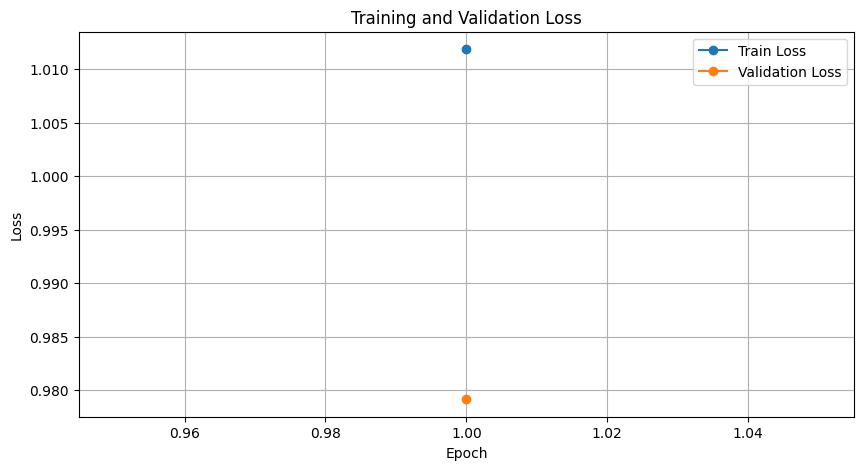

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [41]:
checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_multitask_bert.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()

print("Best Epoch:", checkpoint["epoch"])
print("Best Validation F1:", checkpoint["best_score"])

Best Epoch: 1
Best Validation F1: 0.6534413139291092


In [42]:
test_results = evaluate_model(
    model,
    test_loader
)

print("\nFINAL TEST RESULTS")
print("=" * 50)

print("\nRecommendation Status")

for metric, value in test_results["recommendation"].items():
    print(f"{metric}: {value:.4f}")

print("\nRating Band")

for metric, value in test_results["rating"].items():
    print(f"{metric}: {value:.4f}")

print("\nTest Loss:", round(test_results["loss"], 4))

Evaluating:   0%|          | 0/37562 [00:00<?, ?it/s]


FINAL TEST RESULTS

Recommendation Status
accuracy: 0.8787
precision: 0.7339
recall: 0.7022
f1: 0.7138

Rating Band
accuracy: 0.7457
precision: 0.6792
recall: 0.5605
f1: 0.5924

Test Loss: 0.9805


In [45]:
SAVE_DIR = "/content/drive/MyDrive/project33/trained_model"

os.makedirs(SAVE_DIR, exist_ok=True)

# Save model weights and configuration
torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": MODEL_NAME,
    # "num_classes": num_classes,
    "max_length": MAX_LENGTH,
    "epochs": EPOCHS,
}, os.path.join(SAVE_DIR, "model.pth"))

print("Model saved successfully!")

Model saved successfully!
